In [1]:
# Generacion de los puntos de todos los tamanos del experimento en la carpeta datos
from sklearn.datasets import make_blobs
import numpy as np
import os

os.makedirs("datos", exist_ok=True)

# Indicate the number of points
for n_points in [20000, 40000, 80000, 120000, 140000, 160000, 180000, 200000]:

    # randomly generating data points and noise
    points, y_true = make_blobs(n_samples=n_points,
                                centers=4,
                                cluster_std=0.06,
                                random_state=11,
                                center_box=(0, 1.0))

    # only positive points and with three decimals
    points = np.round(np.abs(points[:, ::-1]), 3)

    # storing points into a csv file
    np.savetxt("datos/"+str(n_points)+"_data.csv", points, delimiter=",",  fmt="%.3f")

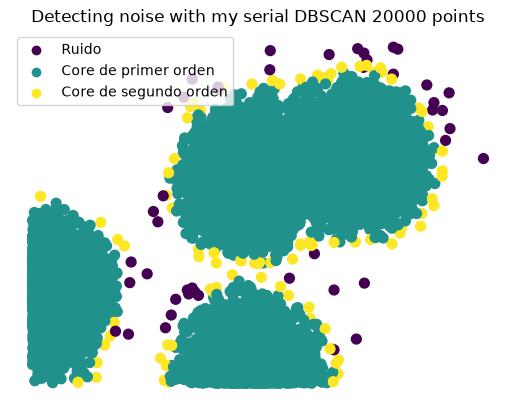

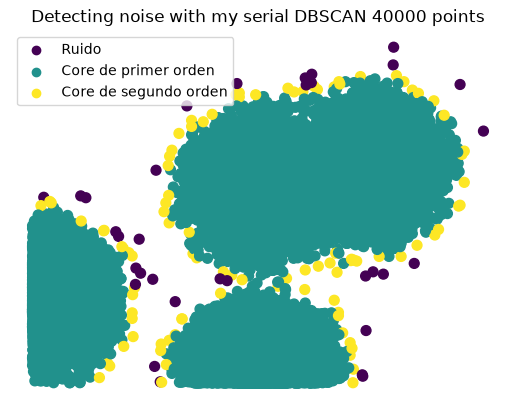

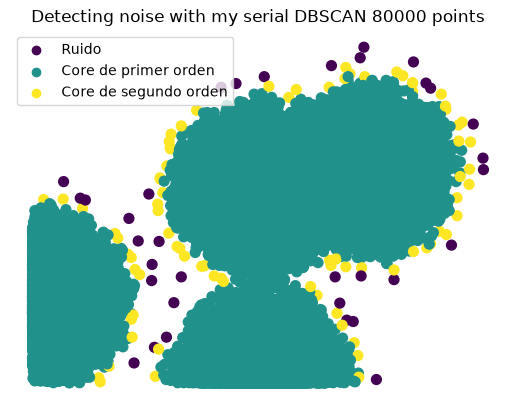

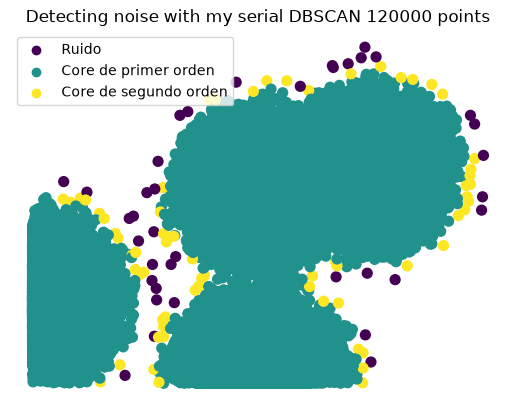

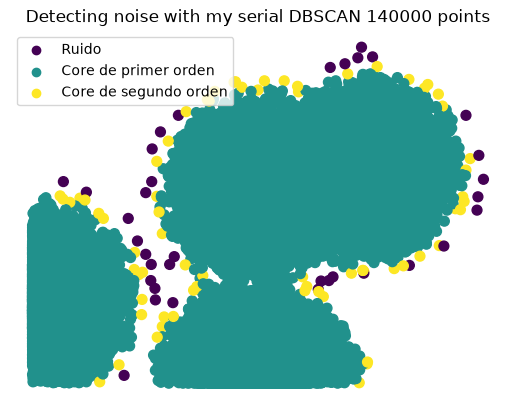

C:\Users\luis_\AppData\Local\Temp\ipykernel_19164\2502687387.py:27: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("graficas/clasificacion_serial_" + str(n_points) + ".png")
c:\Users\luis_\Desktop\9.-SEMESTRE\Minería de datos\ProyectoMineria\ProyectoComputoParalelo\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


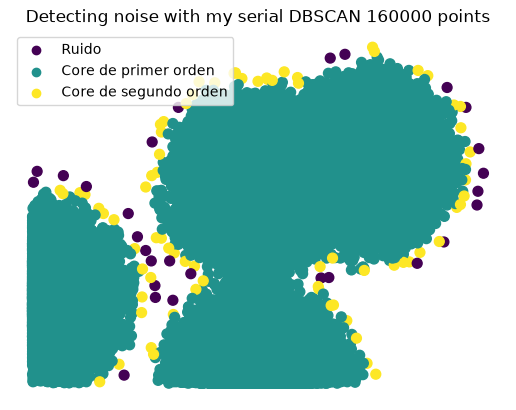

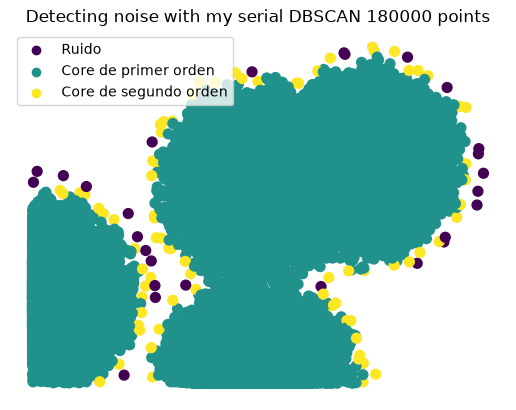

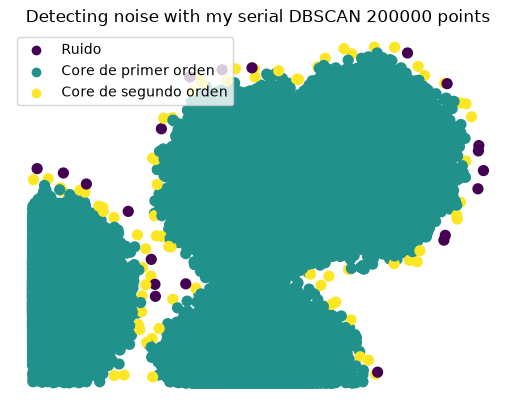

In [3]:
# Visualizacion de los resultados de todos los tamaños guardados en la carpeta datos
import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("graficas", exist_ok=True)

# Indicate the number of points
for n_points in [20000, 40000, 80000, 120000, 140000, 160000, 180000, 200000]:

    # loading results from c++ program into a numpy array
    result = np.loadtxt("datos/"+str(n_points)+"_results.csv", delimiter=",")

    # plotting noise
    plt.figure()
    plt.title("Detecting noise with my serial DBSCAN " + str(n_points) + " points")
    corePrimero = result[result.T[2] == 1]
    coreSegundo = result[result.T[2] == 2]
    ruido = result[result.T[2] == 0]
    plt.scatter(corePrimero.T[0], corePrimero.T[1], s=50, label="Core de primer orden")
    plt.scatter(coreSegundo.T[0], coreSegundo.T[1], s=50, label="Core de segundo orden")
    plt.scatter(ruido.T[0], ruido.T[1], s=50, label="Ruido")
    plt.xticks([])
    plt.yticks([])
    plt.box(False)
    plt.legend()
    plt.savefig("graficas/clasificacion_serial_" + str(n_points) + ".png")
    plt.show()

In [10]:
# Tiempo promedio de la version serial contra el numero de puntos
datosSerial = np.loadtxt("datos/tiempos_serial.csv", delimiter=",", skiprows=1)
tamanos = datosSerial.T[0]
promedios = datosSerial.T[1]

plt.figure()
plt.plot(tamanos, promedios, marker="o")
plt.title("Tiempo promedio de la version serial")
plt.xlabel("Numero de puntos")
plt.ylabel("Segundos")
plt.grid(True)
plt.savefig("graficas/tiempo_serial.png")
plt.show()

In [7]:
# Speedup de P1 con distinto numero de hilos
# Speedup es el tiempo serial entre el tiempo paralelo
datosP1 = np.loadtxt("datos/tiempos_p1.csv", delimiter=",", skiprows=1)

plt.figure()
for hilos in [1, 2, 4, 8]:
    speedups = []
    for i in range(len(tamanos)):
        for fila in datosP1:
            if fila[0] == tamanos[i] and fila[1] == hilos:
                speedups.append(promedios[i] / fila[3])
    plt.plot(tamanos, speedups, marker="o", label=str(hilos) + " hilos")
plt.axhline(1.5, color="gray", linestyle="dashed", label="Meta de speedup 1.5")
plt.title("Speedup de P1")
plt.xlabel("Numero de puntos")
plt.ylabel("Speedup")
plt.grid(True)
plt.legend()
plt.savefig("graficas/speedup_p1.png")
plt.show()

FileNotFoundError: datos/tiempos_p1.csv not found.

In [ ]:
# Speedup de P2 con 4 hilos y distintos valores de k
datosP2 = np.loadtxt("datos/tiempos_p2.csv", delimiter=",", skiprows=1)

plt.figure()
for k in [2, 4, 8, 16, 32, 64]:
    speedups = []
    for i in range(len(tamanos)):
        for fila in datosP2:
            if fila[0] == tamanos[i] and fila[1] == 4 and fila[2] == k:
                speedups.append(promedios[i] / fila[3])
    plt.plot(tamanos, speedups, marker="o", label="k " + str(k))
plt.axhline(1.5, color="gray", linestyle="dashed", label="Meta de speedup 1.5")
plt.title("Speedup de P2 con 4 hilos")
plt.xlabel("Numero de puntos")
plt.ylabel("Speedup")
plt.grid(True)
plt.legend()
plt.savefig("graficas/speedup_p2.png")
plt.show()

In [ ]:
# Comparacion de P1 y P2 con 4 hilos, P2 con k igual a 4
speedupsP1 = []
speedupsP2 = []
for i in range(len(tamanos)):
    for fila in datosP1:
        if fila[0] == tamanos[i] and fila[1] == 4:
            speedupsP1.append(promedios[i] / fila[3])
    for fila in datosP2:
        if fila[0] == tamanos[i] and fila[1] == 4 and fila[2] == 4:
            speedupsP2.append(promedios[i] / fila[3])

plt.figure()
plt.plot(tamanos, speedupsP1, marker="o", label="P1")
plt.plot(tamanos, speedupsP2, marker="o", label="P2 con k 4")
plt.axhline(1.5, color="gray", linestyle="dashed", label="Meta de speedup 1.5")
plt.title("Comparacion de speedup con 4 hilos")
plt.xlabel("Numero de puntos")
plt.ylabel("Speedup")
plt.grid(True)
plt.legend()
plt.savefig("graficas/comparacion.png")
plt.show()